# ¿Se parecen dos frases? El coseno lo decide

**Álgebra Lineal** · Departamento de Ciencias Básicas y Matemáticas · Pontificia Universidad
Javeriana Cali

—

Un buscador tiene que decidir si *«los investigadores programan modelos»* se parece más a
*«los investigadores escriben artículos y gráficas»* o a *«los músicos afinan los
instrumentos»*.

Para decidirlo hay que convertir cada frase en un **vector** y medir el **ángulo** entre
ellos. Eso es todo lo que vamos a hacer hoy.

—

| Parte | Qué hace usted | Puntos | Tiempo |
|---|---|---|---|
| **1** | **Leer y ejecutar.** El código viene hecho. Solo hay que entender de dónde salen los vectores. | — | 15 min |
| **2** | **Comparar dos frases**, paso a paso: sumar, promediar, coseno, interpretar. | **60** | 30 min |
| **3** | Contestar **¿cuántas palabras hacen falta** para armar una frase? | **40** | 25 min |

> **No va a necesitar ningún ciclo.** Cada paso que usted escribe es **una sola línea** de
> NumPy. Si siente que necesita un `for`, le falta una operación vectorial.

> **Autocontenido.** Todo está en este cuaderno: no se descarga ni se instala nada.



# Parte 1 — De dónde salen los vectores

*No se califica. Lea, ejecute y entienda: en las Partes 2 y 3 va a usar estos vectores.*

## 1.1 · El objetivo: volver vector una frase

Un buscador recibe *«los músicos afinan los instrumentos»* y tiene que decidir cuál de las
frases que guarda se le parece más. Un detector de copia tiene que decidir si dos párrafos
dicen lo mismo con otras palabras. Un profesor con $300$ respuestas escritas tiene que
agruparlas por lo que dicen.

Las tres son **la misma pregunta**: ¿qué tan parecidas son dos frases? Y usted ya sabe
responderla **cuando las cosas son vectores**:

$$\cos\theta=\frac{\vec u\cdot\vec v}{\lVert \vec u\rVert \;\lVert \vec v\rVert }$$

cerca de $1$ apuntan en la misma dirección, cerca de $0$ son perpendiculares. El coseno no
sabe de texto: sabe de vectores. Así que todo el trabajo está en **convertir la frase en un
vector** de modo que el ángulo signifique algo.

El plan es de tres pasos, y la Parte 1 es el primero:

| | Paso | Dónde |
|---|---|---|
| 1 | cada **palabra** se vuelve un vector | Parte 1 (ya hecho) |
| 2 | la **frase** es el promedio de los vectores de sus palabras | Parte 2 |
| 3 | el **coseno** entre esos dos vectores responde la pregunta | Parte 2 |

Vamos a seguir una sola frase de ejemplo durante toda esta parte:

> ### «La salsa suena en la plaza y la plaza baila salsa»

## 1.2 · Primero: botar las palabras vacías

En esa frase hay once palabras, pero cinco no aportan nada:

$$\underbrace{\texttt{La}}_{\text{vacía}}\quad\texttt{salsa}\quad\texttt{suena}\quad
  \underbrace{\texttt{en}\quad\texttt{la}}_{\text{vacías}}\quad\texttt{plaza}\quad
  \underbrace{\texttt{y}\quad\texttt{la}}_{\text{vacías}}\quad\texttt{plaza}\quad
  \texttt{baila}\quad\texttt{salsa}$$

Se llaman **palabras vacías** (*stop words*) y se quitan por tres razones:

1. **No dicen de qué habla el texto.** `la`, `en` y `y` aparecen igual en un texto de
   cocina, en uno de física y en este de salsa. No distinguen nada.
2. **Son las más frecuentes y aparecen cerca de todo.** Si las dejamos, *todas* las
   palabras del corpus terminarían compartiendo vecinos con `la` y con `de`, y todos los
   parecidos subirían por igual. El efecto es que **se borra la información** que
   queríamos medir.
3. **Ocupan la ventana.** Vamos a mirar solo unas pocas palabras a cada lado. Si contamos
   `la`, `en` y `y`, el relleno empuja afuera a `baila` —que es justo la que importa—.

Nos queda una secuencia de **seis palabras de contenido**, de las cuales solo **cuatro son
distintas** (`salsa` y `plaza` aparecen dos veces):

$$\underset{0}{\texttt{salsa}}\quad \underset{1}{\texttt{suena}}\quad
  \underset{2}{\texttt{plaza}}\quad \underset{3}{\texttt{plaza}}\quad
  \underset{4}{\texttt{baila}}\quad \underset{5}{\texttt{salsa}}$$

> **El precio de quitarlas:** la distancia se mide ahora **entre palabras de contenido**, no
> en el texto original. En la frase `suena` y `plaza` tenían dos palabras de por medio y
> ahora quedan pegadas. Es una decisión nuestra, y es la que toman casi todos los sistemas
> reales.

## 1.3 · El *one-hot* y por qué no sirve

La forma más simple de volver vector una palabra es **one-hot**: se ordena el vocabulario y
cada palabra recibe un $1$ en su propia posición y $0$ en todas las demás. Con el
vocabulario de nuestra frase, en orden alfabético
$(\texttt{baila},\ \texttt{plaza},\ \texttt{salsa},\ \texttt{suena})$:

$$\texttt{baila}\mapsto(1,0,0,0),\quad
  \texttt{plaza}\mapsto(0,1,0,0),\quad
  \texttt{salsa}\mapsto(0,0,1,0),\quad
  \texttt{suena}\mapsto(0,0,0,1).$$

Mida ahora el coseno de cualquier par: **siempre da $0$**, porque los unos nunca caen en la
misma posición.

$$\cos(\texttt{plaza},\texttt{salsa})=0,\qquad
  \cos(\texttt{baila},\texttt{suena})=0,\qquad
  \cos(\texttt{salsa},\texttt{suena})=0 .$$

**Todas las palabras salen ortogonales entre sí**, a $90^\circ$ unas de otras. El one-hot
sabe *distinguir* palabras, pero no sabe que `plaza` y `salsa` acaban de aparecer una al
lado de la otra, ni que en Cali `salsa` y `baila` van siempre juntas. Como todos los
ángulos son iguales, el coseno no puede ordenar nada: es inservible para nuestra
pregunta.

## 1.4 · El cambio: llenar los ceros con la cercanía

Cambiamos **una sola cosa**. En lugar de poner $0$ en las demás posiciones, ponemos
**qué tan cerca** aparece cada palabra:

> El vector de la palabra $w$ tiene
> - un $\mathbf{1}$ en su propia posición (eso se conserva del one-hot), y
> - en la posición de otra palabra $c$, la suma de $\dfrac{1}{d}$ por **cada vez** que $c$
>   aparece a distancia $d$ de $w$, dentro de una **ventana** de unas pocas palabras a cada
>   lado.
>
> Al final el vector se **normaliza** (se divide por su norma).

El peso $1/d$ dice exactamente lo que queremos: un vecino pegado ($d=1$) aporta $1$; uno a
cinco palabras aporta apenas $1/5$; más lejos de la ventana, nada. Y el *«por cada vez»*
importa: una palabra que aparece dos veces cerca aporta **dos veces**.

### En nuestra frase, con ventana $\pm2$

$$\underset{0}{\texttt{salsa}}\quad \underset{1}{\texttt{suena}}\quad
  \underset{2}{\texttt{plaza}}\quad \underset{3}{\texttt{plaza}}\quad
  \underset{4}{\texttt{baila}}\quad \underset{5}{\texttt{salsa}}$$

Las seis cuentas, una por una. Ojo con las que tienen una palabra repetida: hay que mirar
**las dos apariciones** y sumar.

| par | de dónde sale | total |
|---|---|---|
| `suena` – `plaza` | `plaza` está en $2$ ($d=1\Rightarrow 1$) y en $3$ ($d=2\Rightarrow\tfrac12$) | $\tfrac32$ |
| `plaza` – `baila` | desde `plaza`$_2$ es $d=2\Rightarrow\tfrac12$; desde `plaza`$_3$ es $d=1\Rightarrow 1$ | $\tfrac32$ |
| `salsa` – `suena` | desde `salsa`$_0$ es $d=1\Rightarrow 1$; desde `salsa`$_5$ es $d=4$, **fuera** | $1$ |
| `salsa` – `plaza` | $\tfrac12$ desde cada `salsa` | $1$ |
| `salsa` – `baila` | desde `salsa`$_0$ es $d=4$, **fuera**; desde `salsa`$_5$ es $d=1\Rightarrow 1$ | $1$ |
| `suena` – `baila` | $d=3$: **fuera de la ventana** | $0$ |

$$M=\begin{pmatrix}
1 & \tfrac32 & 1 & 0\\
\tfrac32 & 1 & 1 & \tfrac32\\
1 & 1 & 1 & 1\\
0 & \tfrac32 & 1 & 1
\end{pmatrix}
\qquad\text{\small filas y columnas en el orden }
(\texttt{baila},\texttt{plaza},\texttt{salsa},\texttt{suena})$$

### Qué se ganó

Normalizando las filas y midiendo el coseno:

$$\cos(\texttt{plaza},\texttt{salsa})=\frac{5\sqrt{26}}{26}\approx 0{,}9806,
  \qquad
  \cos(\texttt{baila},\texttt{suena})=\frac{13}{17}\approx 0{,}7647 .$$

Con one-hot los dos valían $0$. Ahora:

- **`plaza` y `salsa` casi coinciden** ($0{,}98$): aparecieron pegadas, y además `salsa`
  está en los dos extremos de la frase, así que su fila es $(1,1,1,1)$ —está igual de cerca
  de todo—.
- **`baila` y `suena` dan $0{,}76$**, y esto es lo interesante: su entrada en $M$ es
  **exactamente $0$**, porque están a distancia $3$ y **nunca caen en la ventana de la
  otra**. Y aun así su coseno es alto, porque **comparten vecinos**: las dos tienen a
  `plaza` y a `salsa` al lado. El modelo dedujo un parecido que no estaba escrito en
  ninguna parte.

> Esa es toda la idea del taller, y la frase para llevarse:
> **una palabra significa con quién aparece.** Dos palabras se parecen cuando aparecen
> rodeadas de las mismas palabras, aunque nunca se encuentren.

En el párrafo real usaremos **ventana $\pm5$** (cinco a la izquierda y cinco a la derecha)
en lugar de $\pm2$.

## 1.5 · El código, completo

Lo que acaba de hacer a mano con cuatro palabras, ahora con un párrafo entero. Ejecute las
cuatro celdas siguientes. **No hay nada que completar**: léalas con el comentario de al
lado y quédese con la idea de cada paso.

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- el párrafo: todo el taller sale de aquí ----------
TEXTO = """Los profesores llegan temprano al laboratorio de ingeniería. En el laboratorio
los investigadores programan modelos, simulan datos y comparan resultados. Por la tarde
los investigadores escriben artículos y preparan gráficas. La noche cubre el centro de
Cali. Frente al teatro los músicos afinan los instrumentos, la trompeta responde al bombo
y la música mueve a la multitud. En la plaza la gente baila y la salsa suena."""

VACIAS = np.array(['la', 'el', 'los', 'las', 'de', 'del', 'en', 'y', 'a', 'al',
                   'un', 'una', 'con', 'por', 'su', 'sus', 'que', 'se', 'es', 'lo'])
SIGNOS = str.maketrans('', '', '.,;:!¿?¡()«»"')
VENTANA = 5

print(TEXTO)

Los profesores llegan temprano al laboratorio de ingeniería. En el laboratorio
los investigadores programan modelos, simulan datos y comparan resultados. Por la tarde
los investigadores escriben artículos y preparan gráficas. La noche cubre el centro de
Cali. Frente al teatro los músicos afinan los instrumentos, la trompeta responde al bombo
y la música mueve a la multitud. En la plaza la gente baila y la salsa suena.


In [2]:
# ---------- PASO A: del texto a una lista de palabras de contenido ----------
tok = np.array(TEXTO.lower().translate(SIGNOS).split())   # minúsculas, sin signos
tok = tok[~np.isin(tok, VACIAS)]                          # fuera las palabras vacías

# vocab = palabras distintas (alfabético) · idx = a qué palabra corresponde cada token
vocab, primera, idx = np.unique(tok, return_index=True, return_inverse=True)
T, V = len(tok), len(vocab)

print(f"T = {T} palabras de contenido · V = {V} palabras distintas\n")
print("la secuencia quedó así:\n ", " ".join(tok))

T = 39 palabras de contenido · V = 37 palabras distintas

la secuencia quedó así:
  profesores llegan temprano laboratorio ingeniería laboratorio investigadores programan modelos simulan datos comparan resultados tarde investigadores escriben artículos preparan gráficas noche cubre centro cali frente teatro músicos afinan instrumentos trompeta responde bombo música mueve multitud plaza gente baila salsa suena


In [4]:
# ---------- PASO B: la matriz de proximidad entre palabras ----------
# O marca, para cada posición del texto, qué palabra del vocabulario está ahí
O = np.eye(V)[idx]                                   # T x V

# Dist[p, q] = a cuántas palabras de distancia están las posiciones p y q
pos = np.arange(T)
Dist = np.abs(pos[:, None] - pos[None, :])           # T x T

# Wm[p, q] = 1/distancia si están dentro de la ventana; 0 si no
Wm = np.where((Dist >= 1) & (Dist <= VENTANA), 1.0 / np.maximum(Dist, 1), 0.0)

# el producto junta las dos cosas: para cada par de PALABRAS, suma los 1/d
M = O.T @ Wm @ O                                     # V x V
np.fill_diagonal(M, 1.0)                             # el 1 que venía del one-hot

print("O:", O.shape, "· Dist:", Dist.shape, "· Wm:", Wm.shape, "· M:", M.shape)

O: (39, 37) · Dist: (39, 39) · Wm: (39, 39) · M: (37, 37)


In [5]:
# ---------- PASO C: normalizar ----------
# cada fila se divide por su norma: así una palabra frecuente no sale
# «parecida a todo» solo por ser frecuente
Mn = M / np.linalg.norm(M, axis=1, keepdims=True)

print("¿todas las filas quedaron de norma 1?", np.allclose(np.linalg.norm(Mn, axis=1), 1))
print()
print("ejemplo — el vector de 'investigadores' (solo sus entradas no nulas):")
fila = Mn[np.where(vocab == 'investigadores')[0][0]]
print(np.column_stack([vocab[fila > 0], np.round(fila[fila > 0], 3)]))

¿todas las filas quedaron de norma 1? True

ejemplo — el vector de 'investigadores' (solo sus entradas no nulas):
[['artículos' '0.178']
 ['comparan' '0.19']
 ['datos' '0.178']
 ['escriben' '0.355']
 ['gráficas' '0.089']
 ['ingeniería' '0.178']
 ['investigadores' '0.355']
 ['laboratorio' '0.474']
 ['llegan' '0.071']
 ['modelos' '0.178']
 ['noche' '0.071']
 ['preparan' '0.118']
 ['programan' '0.355']
 ['resultados' '0.178']
 ['simulan' '0.19']
 ['tarde' '0.355']
 ['temprano' '0.089']]


### Qué acaba de pasar

La fila de `investigadores` dice: *«aparezco cerca de `laboratorio`, `programan`,
`modelos`, `escriben`…»*, y cada número mide **qué tan cerca**. Ese es el vector de la
palabra.

Fíjese en `laboratorio`: es **la entrada más alta de la fila**, por encima incluso de
`investigadores` consigo misma. En la matriz $M$, antes de normalizar, vale
$\tfrac13+1=\tfrac43$, porque `laboratorio` aparece **dos veces** cerca de
`investigadores` —una a distancia $3$ y otra a distancia $1$—. Es exactamente la regla del
*«por cada vez»* de §1.4. (Los números que ve impresos son los de $M_n$, es decir los de
$M$ divididos por la norma de la fila: cambian de escala, no de orden.)

Dos palabras se parecerán cuando sus filas apunten en la misma dirección, es decir cuando
**aparezcan rodeadas de las mismas palabras**. Esa es toda la idea.

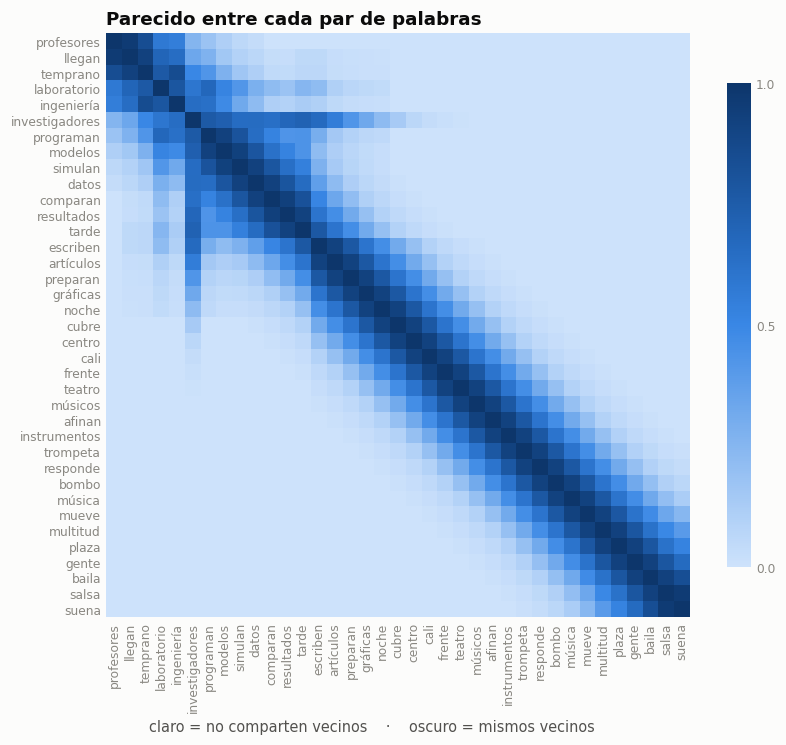

In [6]:
# ---------- el mapa de parecidos entre todas las palabras ----------
COS = Mn @ Mn.T                      # todos los cosenos de una vez
orden = np.argsort(primera)          # las palabras en el orden en que aparecen

TINTA, SUAVE, TENUE, FONDO = '#0b0b0b', '#52514e', '#898781', '#fcfcfb'
from matplotlib.colors import LinearSegmentedColormap
CMAP = LinearSegmentedColormap.from_list(
    'azul', ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'])
plt.rcParams.update({'figure.facecolor': FONDO, 'axes.facecolor': FONDO,
                     'axes.titlecolor': TINTA, 'axes.titlesize': 12,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'xtick.color': TENUE, 'ytick.color': TENUE,
                     'xtick.labelsize': 8, 'ytick.labelsize': 8, 'figure.dpi': 110})

fig, ax = plt.subplots(figsize=(7.8, 7.0))
im = ax.imshow(COS[np.ix_(orden, orden)], cmap=CMAP, vmin=0, vmax=1)
ax.set_xticks(np.arange(V), vocab[orden], rotation=90)
ax.set_yticks(np.arange(V), vocab[orden])
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title('Parecido entre cada par de palabras')
cb = fig.colorbar(im, ax=ax, shrink=0.72, ticks=[0, 0.5, 1])
cb.outline.set_visible(False); cb.ax.tick_params(length=0, colors=TENUE)
fig.text(0.44, 0.015, 'claro = no comparten vecinos    ·    oscuro = mismos vecinos',
         ha='center', fontsize=9.5, color=SUAVE)
plt.tight_layout(); plt.show()

### Lo que muestra el mapa

- Hay una **banda oscura sobre la diagonal**: las palabras vecinas en el texto comparten
  casi toda su ventana.
- Las **dos esquinas están en blanco**. El párrafo tiene dos mitades —el laboratorio por la
  mañana, el teatro y la plaza por la noche— separadas por más de cinco palabras de
  contenido. Ninguna palabra de una mitad cae jamás en la ventana de la otra, así que su
  producto punto es **exactamente cero**: son ortogonales.
- `investigadores` tiene una **cruz oscura** que se sale de la banda. Es porque aparece
  **dos veces** (posiciones $6$ y $14$), separadas por ocho palabras: su ventana cubre un
  tramo mucho más largo que el de las demás, y por eso se parece a más palabras. Una
  palabra repetida «ve» más texto.

Esa es la señal que vamos a aprovechar en la Parte 2.

—
# Parte 2 — ¿Se parecen dos frases? · 60 puntos · ≈30 min

**Esta parte sí se califica.** Vamos paso a paso.

Una frase no es una palabra: tiene varias. La receta es la más simple posible:

> **Sume** los vectores de sus palabras y **divida entre el número de palabras**. Ese
> promedio es el vector de la frase.

Trabajaremos con estas tres:

| | Frase | Palabras de contenido |
|---|---|---|
| **A** | los investigadores programan modelos | `investigadores` `programan` `modelos` |
| **B** | los investigadores escriben artículos y gráficas | `investigadores` `escriben` `artículos` `gráficas` |
| **C** | los músicos afinan los instrumentos | `músicos` `afinan` `instrumentos` |

## Paso 1 · Buscar el vector de una palabra · 8 puntos

`vocab` está ordenado alfabéticamente. Para encontrar la fila de una palabra:

```python
np.where(vocab == 'investigadores')[0][0]   # la posición de esa palabra
Mn[posición]                                 # su vector
```

**(a)** Guarde en `v_inv`, `v_prog` y `v_mod` los vectores de `investigadores`,
`programan` y `modelos`.

In [7]:
i_inv = np.where(vocab == 'investigadores')[0][0]
i_prog = np.where(vocab == 'programan')[0][0]        # COMPLETAR
i_mod = np.where(vocab =='modelos')[0][0]              # COMPLETAR

v_inv = Mn[i_inv]
v_prog = Mn[i_prog]             # COMPLETAR
v_mod = Mn[i_mod]             # COMPLETAR

print("cada vector tiene", v_inv.shape[0], "componentes (una por palabra del vocabulario)")
print("y norma 1:", np.round([np.linalg.norm(v_inv),
                              np.linalg.norm(v_prog),
                              np.linalg.norm(v_mod)], 6))

cada vector tiene 37 componentes (una por palabra del vocabulario)
y norma 1: [1. 1. 1.]


## Paso 2 · Sumar · 8 puntos

**(b)** Sume los tres vectores de la frase **A** y guarde el resultado en `suma_A`.

$$\text{suma}_A=\vec v_{\texttt{investigadores}}+\vec v_{\texttt{programan}}+\vec v_{\texttt{modelos}}$$

In [9]:
suma_A = v_inv + v_prog + v_mod            # COMPLETAR

print("norma de la suma:", round(float(np.linalg.norm(suma_A)), 4))

norma de la suma: 2.7958


## Paso 3 · Promediar · 8 puntos

**(c)** Divida entre $3$ —el número de palabras— y guarde el promedio en `A`.

$$\vec f_A=\frac{\vec v_{\texttt{investigadores}}+\vec v_{\texttt{programan}}+\vec v_{\texttt{modelos}}}{3}$$

*¿Por qué promediar y no solo sumar?* Para que una frase larga no salga automáticamente
«más grande» que una corta. El promedio deja el vector **a la escala de una palabra**.

In [10]:
A = suma_A / 3                   # COMPLETAR: la suma dividida entre 3

print("norma del promedio:", round(float(np.linalg.norm(A)), 4))
print("norma de la suma   :", round(float(np.linalg.norm(suma_A)), 4))
print("la suma es", round(float(np.linalg.norm(suma_A)/np.linalg.norm(A)), 2), "veces más larga")

norma del promedio: 0.9319
norma de la suma   : 2.7958
la suma es 3.0 veces más larga


## Paso 4 · Hacer lo mismo con las otras dos frases · 10 puntos

**(d)** Arme `B` (promedio de `investigadores`, `escriben`, `artículos`, `gráficas`) y `C`
(promedio de `músicos`, `afinan`, `instrumentos`). **Ojo: `B` tiene cuatro palabras**, así
que se divide entre $4$; `C` tiene tres.

In [19]:
B = (Mn[np.where(vocab == 'investigadores')[0][0]] +
     Mn[np.where(vocab == 'escriben')[0][0]] +
     Mn[np.where(vocab == 'artículos')[0][0]] +
     Mn[np.where(vocab == 'gráficas')[0][0]]) / 4.0 #COMPLETAR


C = (Mn[np.where(vocab == 'músicos')[0][0]] +
     Mn[np.where(vocab == 'afinan')[0][0]] +
     Mn[np.where(vocab == 'instrumentos')[0][0]]) / 3.0 #COMPLETAR

print("norma de A:", round(float(np.linalg.norm(A)), 4))
print("norma de B:", round(float(np.linalg.norm(B)), 4))
print("norma de C:", round(float(np.linalg.norm(C)), 4))

norma de A: 0.9319
norma de B: 0.8544
norma de C: 0.9557


## Paso 5 · El coseno · 12 puntos

Ya es la fórmula de siempre:

$$\cos\theta=\frac{\vec u\cdot\vec v}{\lVert \vec u\rVert \;\lVert \vec v\rVert }$$

En NumPy: `u @ v / (np.linalg.norm(u) * np.linalg.norm(v))`.

**(e)** Calcule los tres cosenos: `cos_AB`, `cos_AC` y `cos_BC`, y sus tres ángulos en
grados. *Para el ángulo: `np.degrees(np.arccos(np.clip(c, -1, 1)))`.*

In [20]:
cos_AB = A @ B / (np.linalg.norm(A) * np.linalg.norm(B))              # COMPLETAR
cos_AC = A @ C / (np.linalg.norm(A) * np.linalg.norm(C))             # COMPLETAR
cos_BC = B @ C / (np.linalg.norm(B) * np.linalg.norm(C))              # COMPLETAR

ang_AB = np.degrees(np.arccos(np.clip(cos_AB, -1, 1)))              # COMPLETAR
ang_AC = np.degrees(np.arccos(np.clip(cos_AC, -1, 1)))# COMPLETAR
ang_BC = np.degrees(np.arccos(np.clip(cos_BC, -1, 1)))              # COMPLETAR

print(f"A vs B   cos = {cos_AB:.4f}   ángulo = {ang_AB:6.2f}°")
print(f"A vs C   cos = {cos_AC:.4f}   ángulo = {ang_AC:6.2f}°")
print(f"B vs C   cos = {cos_BC:.4f}   ángulo = {ang_BC:6.2f}°")

A vs B   cos = 0.5137   ángulo =  59.09°
A vs C   cos = 0.0000   ángulo =  90.00°
B vs C   cos = 0.0219   ángulo =  88.75°


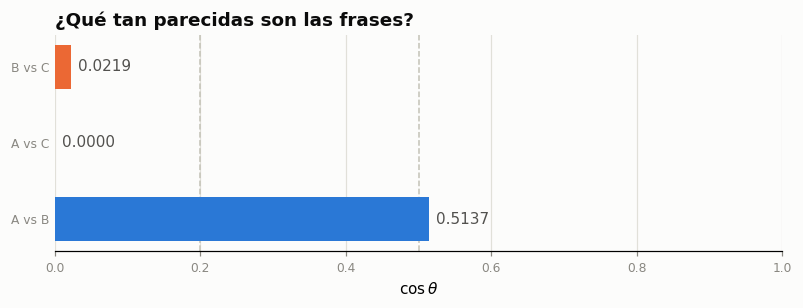

In [21]:
# --- la figura (ya viene hecha) ---
AZUL, NARANJA, AGUA = '#2a78d6', '#eb6834', '#1baf7a'
pares = np.array(['A vs B', 'A vs C', 'B vs C'])
vals = np.array([cos_AB, cos_AC, cos_BC])
colores = np.where(vals >= 0.5, AZUL, np.where(vals >= 0.2, AGUA, NARANJA))

fig, ax = plt.subplots(figsize=(7.4, 2.9))
barras = ax.barh(np.arange(3), vals, height=0.58, color=colores, zorder=3)
ax.bar_label(barras, fmt='%.4f', padding=5, fontsize=10, color='#52514e')
ax.set_yticks(np.arange(3), pares)
ax.set_xlim(0, 1.0)
ax.axvline(0.5, color='#c3c2b7', linewidth=1, linestyle='--', zorder=1)
ax.axvline(0.2, color='#c3c2b7', linewidth=1, linestyle='--', zorder=1)
ax.set_xlabel(r'$\cos\theta$')
ax.set_title('¿Qué tan parecidas son las frases?')
ax.grid(axis='x', zorder=0, color='#e1e0d9')
ax.set_axisbelow(True)
ax.spines['left'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='y', length=0)
plt.tight_layout(); plt.show()

## Paso 6 · Interpretar · 14 puntos

Esta tabla es la que hay que saber leer:

| $\cos\theta$ | Ángulo | Qué significa |
|---|---|---|
| cerca de $1$ | cerca de $0^\circ$ | las frases usan palabras que aparecen **en los mismos contextos**: hablan de lo mismo |
| alrededor de $0{,}5$ | alrededor de $60^\circ$ | comparten **parte** del vocabulario o del contexto |
| cerca de $0$ | cerca de $90^\circ$ | **no comparten nada**: son temas ajenos |

> En este modelo el coseno **nunca es negativo**, porque todas las entradas de $M$ son
> $\ge0$. Los ángulos viven entre $0^\circ$ y $90^\circ$, y $90^\circ$ es el desacuerdo
> máximo posible.

**(f)** Conteste, en dos o tres líneas cada una:

1. ¿Cuál par de frases es el más parecido? Diga el coseno y el ángulo, y diga **en qué
   fila de la tabla cae**. Explique **por qué** mirando las palabras de las dos frases.


2. El par **A vs C** da un coseno de **exactamente** cero. ¿Qué significa eso, en términos
   del párrafo? ¿Por qué es cero exacto y no «casi cero»?
3. Si el buscador recibe la consulta *«los investigadores escriben artículos y gráficas»*,
   ¿qué frase le devolvería primero? ¿Por qué?

> *Su respuesta:*

1. El par de frases mas parecido es A vs B y cae en la segunda fila ya que su cos = 0.5137 lo que indica que esta alrededor de 0.5  ( como indica la tabla) y su  ángulo =  59.09° lo cual indica que esta cercano a 60 cayendo en la segunda categoria ( comparten parte del vocabulario o del contexto).y a partir del contexto de las dos frases esto ocurre porque ambas comparten la palabra investigadores y se refieren a actividades del laboratorio en la misma mitad del texto.

2. En terminos de la tabla no comparten nada y por lo tanto son temas ajenos, da exactamente 0 porque el producto punto entre A y C da 0.

3. Le devolvería la frase B, ya que al ser idéntica a la frase, su coseno daría 1. Entre A y C, le devolvería la A porque comparte la palabra investigadores y el contexto del laboratorio,

In [22]:
# --- una observación que vale la pena mirar ---
# ¿qué pasa si NO promediamos y usamos la suma?
cos_suma = suma_A @ B / (np.linalg.norm(suma_A) * np.linalg.norm(B))

print(f"con el promedio A : cos = {cos_AB:.10f}")
print(f"con la suma  suma_A: cos = {cos_suma:.10f}")
print()
print("¿son iguales?", np.isclose(cos_AB, cos_suma))

con el promedio A : cos = 0.5137369383
con la suma  suma_A: cos = 0.5137369383

¿son iguales? True


**(g)** La celda anterior muestra que **la suma y el promedio dan exactamente el mismo
coseno**, aunque sus normas sean distintas (una es $3$ veces la otra). Explique por qué.

*Pista: escriba $\vec f_A=\tfrac13\,\text{suma}_A$ y reemplace en la fórmula del coseno.*

> *Su respuesta:*
Si reemplazamos ese escalas (1/3) en la formula del coseno tanto en el numerador como en el denominador, aunque el resultado de la magnitud cambie la direccion de este vector permanece igual.

—
# Parte 3 — ¿Cuántas palabras hacen falta? · 40 puntos · ≈25 min

Hasta aquí midió **ángulos**. Ahora una pregunta distinta, de las de sistemas de
ecuaciones.

La frase **A** se armó con tres palabras. Pregunta: **¿con cuántas de ellas alcanza para
reconstruirla?** Es decir, ¿para qué conjunto de palabras existen números $c_1,c_2,\dots$
tales que

$$\boxed{\;c_1\,\vec v_{\texttt{palabra}_1}+c_2\,\vec v_{\texttt{palabra}_2}+\cdots =\vec f_A\;}$$

Poniendo las palabras como **columnas** de una matriz $P$, eso es la ecuación de siempre:

$$P\vec c=\vec f_A .$$

Y responderla es preguntar si $\vec f_A$ está en
$\operatorname{gen}\{\text{las columnas de } P\}$. Vamos a probar con **dos**, con **tres** y con
**cuatro** columnas, y a mirar qué pasa cada vez.

El criterio es el de siempre: **comparar el número de pivotes** de $P$ con el de
$[\,P\mid\vec f_A\,]$. `numpy` los cuenta con `np.linalg.matrix_rank`.

## Caso 1 · Dos palabras · 14 puntos

Nos quedamos solo con `investigadores` y `programan`. La matriz tiene dos columnas.

**(a)** Cuente los pivotes de $P_2$ y de $[\,P_2\mid\vec f_A\,]$. · 6 pts

**(b)** Resuelva con `lstsq` y **verifique**. · 8 pts

In [24]:
P2 = np.column_stack([v_inv, v_prog])          # 2 columnas
A2 = np.column_stack([P2, A])

piv_P2 = np.linalg.matrix_rank(P2)
piv_A2 = np.linalg.matrix_rank(A2)              # COMPLETAR: pivotes de [P2 | A]
                          # pista: np.column_stack([P2, A])

print("pivotes de P2        :", piv_P2)
print("pivotes de [P2 | f_A]:", piv_A2)
print("¿son iguales?        :", piv_P2 == piv_A2)

c2 = np.linalg.lstsq(P2, A, rcond=None)[0]

print()
print("lstsq devuelve c =", np.round(c2, 6))
print("¿P2 @ c = f_A?   :", ...)            # COMPLETAR: use np.allclose
print("residuo          :", round(float(np.linalg.norm(P2 @ c2 - A)), 6))

pivotes de P2        : 2
pivotes de [P2 | f_A]: 3
¿son iguales?        : False

lstsq devuelve c = [0.354711 0.623243]
¿P2 @ c = f_A?   : Ellipsis
residuo          : 0.130982


**(c)** Conteste: ¿qué dice el conteo de pivotes? ¿Y por qué `lstsq` devolvió dos
números a pesar de todo? · incluido en los 8 pts de (b)

> *Su respuesta: los pivotes contados nos indica que el sistema no tiene solución exacta. pero, lstsq devuelve dos números porque utiliza  los mínimos cuadrados para encontrar la mejor aproximación posible minimizando el error.

## Caso 2 · Tres palabras · 12 puntos

Agregamos `modelos`, la palabra que faltaba.

**(d)** Repita el conteo de pivotes y la verificación con las tres columnas.

In [25]:
P3 = np.column_stack([v_inv, v_prog, v_mod])   # 3 columnas
A3 = np.column_stack([P3, A])
piv_P3 = np.linalg.matrix_rank(P3)              # COMPLETAR
piv_A3 = np.linalg.matrix_rank(A3)              # COMPLETAR: pivotes de [P3 | A]

c3 = np.linalg.lstsq(P3, A, rcond=None)[0]

print("pivotes de P3        :", piv_P3)
print("pivotes de [P3 | f_A]:", piv_A3)
print()
print("c =", np.round(c3, 6))
print("¿P3 @ c = f_A?   :", np.allclose(P3 @ c3, A))
print("residuo          :", round(float(np.linalg.norm(P3 @ c3 - A)), 6))

pivotes de P3        : 3
pivotes de [P3 | f_A]: 3

c = [0.333333 0.333333 0.333333]
¿P3 @ c = f_A?   : True
residuo          : 0.0


**(e)** Los tres coeficientes dieron el mismo número. ¿Cuál es, y **por qué era de
esperarse**? Mire cómo definió $\vec f_A$ en el Paso 3. Y diga por qué la solución es
**única**.

> *Su respuesta:*El 0.33333. Era de esperarse porque elvector fA due definió como el promedio de tres palabras y su solución es única porque las tres columnas son linealmente independientes.  

## Caso 3 · Una palabra de sobra · 14 puntos

¿Y si agregamos una **cuarta** palabra que no está en la frase? Tomemos `datos`, que está
en la misma mitad del párrafo pero no aparece en **A**.

**(f)** Repita el conteo y la verificación con las cuatro columnas. · 6 pts

In [26]:
v_datos = Mn[np.where(vocab == 'datos')[0][0]]
P4 = np.column_stack([v_inv, v_prog, v_mod, v_datos])   # 4 columnas
A4 = np.column_stack([P4, A])
piv_P4 = np.linalg.matrix_rank(P4)               # COMPLETAR
piv_A4 = np.linalg.matrix_rank(A4)              # COMPLETAR

c4 = np.linalg.lstsq(P4, A, rcond=None)[0]

print("pivotes de P4        :", piv_P4)
print("pivotes de [P4 | f_A]:", piv_A4)
print()
print("c =", np.round(c4, 6))
print("¿P4 @ c = f_A?   :", np.allclose(P4 @ c4, A))

pivotes de P4        : 4
pivotes de [P4 | f_A]: 4

c = [0.333333 0.333333 0.333333 0.      ]
¿P4 @ c = f_A?   : True


**(g)** Conteste: · 8 pts

1. ¿Qué pasó con el número de pivotes al agregar `datos`? ¿El sistema sigue siendo
   consistente?
2. El cuarto coeficiente salió $0$. ¿Qué está diciendo el sistema con ese cero?
3. Junte los tres casos y responda la pregunta del título: **¿cuántas palabras hacen
   falta?** ¿Qué pasa si sobran?

> *Su respuesta:* Aquí tienes el resumen directo para tus respuestas de la Parte 3 (g):

1. El número de pivotes aumentó a cuatro y se mantuvo igual en ambas matrices, el sistema sigue siendo consistent.


2.  Indica que la palabra sobrante no es necesaria para reconstruir la frase, por lo que el sistema le asigna un peso nulo.


3.Hacen falta exactamente tres palabras para una solución exacta. Si hacen faltan, el sistema no tiene solucion si sobran, sigue siendo consistente, pero las palabras extra reciben un resultado de cero.

—
# Para cerrar

| Lo que hizo | La operación |
|---|---|
| Vector de una palabra | fila de $M_n$: con quién aparece y qué tan cerca |
| Vector de una frase | sumar los vectores de sus palabras y dividir entre cuántas son |
| ¿Se parecen dos frases? | $\cos\theta=\dfrac{\vec u\cdot\vec v}{\lVert \vec u\rVert \lVert \vec v\rVert }$ · cerca de $1$ se parecen, cerca de $0$ no |
| ¿Cuántas palabras hacen falta? | $P\vec c=\vec f$ · comparar pivotes de $P$ y de $[\,P\mid\vec f\,]$, agregando columnas |

**Las tres frases para llevarse:**

1. Una palabra significa **con quién aparece**. Y «con quién aparece» es un vector, así que
   el parecido entre palabras es un **ángulo**.
2. Agregar columnas **nunca** vuelve inconsistente un sistema consistente; quitarlas sí.
3. Una rutina que siempre responde no es una rutina que siempre tiene razón: **verifique**.